# The realized EA/SW-IO forecast store on source.coop

[`ecmwf-ifs-ea-swio-realized-v3`](https://source.coop/e4drr-project/forecasts/ecmwf-ifs-ea-swio-realized-v3)
holds ECMWF IFS ensemble forecasts for East Africa and the south-west Indian
Ocean, **decoded and materialized** as an Icechunk store. It is built for **Continuous Risk Monitoring and Assessment (CRMA)**, for
**epistemic / Bayesian reasoning about risk**, and for training convective
models (**cGAN**) over the region.

All three depend on the same property: the store keeps **every one of the 51
ensemble members** rather than a mean. The spread between members *is* the
forecast uncertainty — the quantity a Bayesian treatment updates on, and the
distribution a cGAN learns to sample from. A deterministic store would have
discarded it.

It is a different kind of thing from the *virtual* GIK store
(`ecmwf_ifs_ens_aws_s3_icechunk_vd`), and the difference is what makes it easy
to use:

| | virtual store | **this store** |
|---|---|---|
| what a chunk is | a byte range in a GRIB file on AWS | **real float32 data** |
| domain | global, 721 x 1440 | **EA/SW-IO, 321 x 261** |
| variables | 19-59 raw ECMWF short names | **38 model-ready channels** |
| needs `gribberish` | yes, or opening fails | **no** |
| needs virtual-chunk auth | yes (`s3://ecmwf-forecasts/`) | **no** |
| needs credentials | no (but two anonymous hops) | **no** |

So: `icechunk` + `zarr` + `xarray`, anonymous, one hop. Nothing else.

Everything below is executed against the live store.

**Sections 1-9** are the store itself. **Sections 10-13** then use it the way CRMA does: the six evidence nodes, the basins and synoptic boxes they
are reduced onto, one initialisation carried from grid to table with the
arithmetic shown, and what the Bayesian network does with the result.


## Dependencies

```
icechunk>=2.1  zarr>=3.2  xarray>=2025.1  numpy  pandas  matplotlib
```

Note what is **absent**: no `gribberish`, no `s3fs`, no AWS credentials. The
chunks are ordinary compressed arrays.


In [1]:
# Dependency check -- this store needs no GRIB decoder, but it does need these.
import importlib, sys
need = ["icechunk", "zarr", "xarray", "boto3", "numpy", "pandas", "matplotlib"]
missing = [m for m in need if importlib.util.find_spec(m) is None]
if missing:
    print("MISSING:", ", ".join(missing))
    print("Install into THIS kernel with:")
    print(f"  %pip install {' '.join(missing)}")
    print(f"\nkernel: {sys.executable}")
else:
    print("all dependencies present")
    print("kernel:", sys.executable)

all dependencies present
kernel: /var/lib/nishadhka/grib-index-kerchunk/icechunk-dask-frisky/.venv/bin/python


In [2]:
%matplotlib inline
import asyncio
import time

import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import icechunk
import xarray as xr
from botocore import UNSIGNED
from botocore.config import Config

print("icechunk", icechunk.__version__)
print("xarray  ", xr.__version__)


icechunk 2.1.1
xarray   2026.7.0


## 1. Open a sub-store, anonymously

The store is split into **sub-stores, one per season**, because an Icechunk
store fixes its `time` axis at creation. Each is a separate repo under the same
prefix.

Four settings matter, and three of them are not obvious:

- `anonymous=True` — public read, no keys.
- `from_env=False` — ignore any `AWS_*` in the environment. Without this a
  stray `AWS_ENDPOINT_URL` silently redirects the open.
- `force_path_style=True` — source.coop needs path-style addressing.
- **manifest preload off** — the default open prefetches thousands of manifests
  in parallel, and source.coop returns sporadic 500s; one failure aborts the
  whole open.


In [3]:
ENDPOINT = "https://data.source.coop"
BUCKET   = "e4drr-project"
BASE     = "forecasts/ecmwf-ifs-ea-swio-realized-v3"


def open_sub(sub):
    """-> (repo, session, dataset) for one season sub-store. No credentials."""
    storage = icechunk.s3_storage(
        bucket=BUCKET, prefix=f"{BASE}/{sub}", endpoint_url=ENDPOINT,
        region="us-east-1",
        anonymous=True,          # public read
        from_env=False,          # ignore ambient AWS_* vars
        force_path_style=True,   # source.coop requires it
    )
    cfg = icechunk.RepositoryConfig.default()
    cfg.manifest = icechunk.ManifestConfig(
        preload=icechunk.ManifestPreloadConfig(max_total_refs=0,
                                               max_arrays_to_scan=0))
    repo = icechunk.Repository.open(storage, config=cfg)
    session = repo.readonly_session("main")
    # chunks={} is dask-backed and LAZY. chunks=None would load eagerly, and
    # concatenating two whole seasons would then try to allocate ~34 GiB.
    ds = xr.open_zarr(session.store, zarr_format=3, consolidated=False,
                      chunks={}, decode_timedelta=True)
    return repo, session, ds


t0 = time.time()
repo, sess, ds = open_sub("49r1-jja2025")
print(f"opened in {time.time() - t0:.1f}s\n")
print(ds)


opened in 3.5s

<xarray.Dataset> Size: 4TB
Dimensions:    (time: 92, step: 65, number: 51, latitude: 321, longitude: 261)
Coordinates:
  * time       (time) datetime64[ns] 736B 2025-06-01 2025-06-02 ... 2025-08-31
  * step       (step) timedelta64[s] 520B 0 days 00:00:00 ... 10 days 00:00:00
  * number     (number) int64 408B 0 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * latitude   (latitude) float64 3kB 40.0 39.75 39.5 ... -39.5 -39.75 -40.0
  * longitude  (longitude) float64 2kB 15.0 15.25 15.5 15.75 ... 79.5 79.75 80.0
Data variables: (12/38)
    cape       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    d700       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    d850       (time, step, number, latitude, longitude) float32 102GB dask.array<chunksize=(1, 1, 51, 321, 261), meta=np.ndarray>
    lsm        (time, step, number, latitude, longi

## 2. What seasons exist

List the sub-stores rather than assuming them — seasons are added over time.


In [4]:
s3 = boto3.client("s3", endpoint_url=ENDPOINT, region_name="us-east-1",
                  config=Config(signature_version=UNSIGNED,
                                s3={"addressing_style": "path"},
                                max_pool_connections=16))

r = s3.list_objects_v2(Bucket=BUCKET, Prefix=BASE + "/", Delimiter="/")
SUBS = sorted(p["Prefix"].split("/")[-2] for p in r.get("CommonPrefixes", []))
print(f"{len(SUBS)} sub-stores:")
for s in SUBS:
    print("   ", s)


8 sub-stores:
    49r1-jja2024
    49r1-jja2025
    49r1-mam2024
    49r1-mam2025
    49r1-mam2026
    50r1-jja2026
    50r1-jja2026-tail
    50r1-mam2026-tail


Read the names as `{era}-{season}{year}`:

- **era** — the ECMWF model cycle the source came from. `49r1` runs to
  2026-05-12; `50r1` from 2026-05-13. Grid and channels are identical across
  both, so the split is bookkeeping, not a data difference.
- **`-tail`** — a season that straddles an era boundary, or that ran past the
  end of the source at build time, continues in a second store. Section 6
  concatenates them.


## 3. Inventory: days, channels, size, history

`repo.ancestry()` walks the commit history — one commit per date written, so
the snapshot count is an audit trail of how the season was built. Object counts
and bytes come from listing the prefix.

This first table is metadata only and takes seconds. Bytes on disk are
a separate, optional step -- see below.


In [5]:
# Metadata only -- no object listing. A few seconds per sub-store.
rows = []
for sub in SUBS:
    repo_i, sess_i, ds_i = open_sub(sub)
    t = pd.to_datetime(ds_i.time.values)
    rows.append(dict(
        sub=sub, days=len(t), channels=len(ds_i.data_vars),
        steps=ds_i.sizes["step"], members=ds_i.sizes["number"],
        first=str(t.min().date()), last=str(t.max().date()),
        snapshots=len(list(repo_i.ancestry(branch="main"))),
    ))

inv = pd.DataFrame(rows)
print(inv.to_string(index=False))
print(f"\nTOTAL  {inv.days.sum()} forecast days across {len(inv)} sub-stores")

              sub  days  channels  steps  members      first       last  snapshots
     49r1-jja2024    92        38     65       51 2024-06-01 2024-08-31         94
     49r1-jja2025    92        38     65       51 2025-06-01 2025-08-31         94
     49r1-mam2024    92        38     65       51 2024-03-01 2024-05-31        291
     49r1-mam2025    92        38     65       51 2025-03-01 2025-05-31        187
     49r1-mam2026    73        38     65       51 2026-03-01 2026-05-12        224
     50r1-jja2026    33        38     65       51 2026-06-01 2026-07-03         35
50r1-jja2026-tail    51        38     65       51 2026-07-04 2026-08-23         53
50r1-mam2026-tail    19        38     65       51 2026-05-13 2026-05-31         41

TOTAL  544 forecast days across 8 sub-stores


### Optional: bytes on disk

The table above needs only metadata. Getting **actual stored bytes** means
listing every object -- about 1.4 million of them -- which is by far the
slowest thing in this notebook.

Two ways to avoid waiting:

- **Skip it.** Set `MEASURE_BYTES = False` and the published figures below are
  used instead. Everything else in the notebook still runs.
- **Measure it in parallel.** Listing is pure I/O, so running the eight
  sub-stores concurrently cuts it from ~25 minutes to ~3-4.

The published figures were measured on 2026-08-31 and only change when a new
season is added.

In [6]:
MEASURE_BYTES = False        # True -> list ~1.4M objects (~3-4 min, parallel)

# Measured 2026-08-31. Only changes when a season is added.
PUBLISHED_GB = {
    "49r1-mam2024": 1651.75, "49r1-mam2025": 1592.77, "49r1-mam2026": 1329.83,
    "50r1-mam2026-tail": 323.62, "49r1-jja2024": 1551.41, "49r1-jja2025": 1557.37,
    "50r1-jja2026": 560.09, "50r1-jja2026-tail": 857.06,
}

def prefix_bytes(sub):
    """Total bytes under one sub-store. One boto3 client per thread."""
    cl = boto3.client("s3", endpoint_url=ENDPOINT, region_name="us-east-1",
                      config=Config(signature_version=UNSIGNED,
                                    s3={"addressing_style": "path"},
                                    max_pool_connections=8))
    n = size = 0
    for page in cl.get_paginator("list_objects_v2").paginate(
            Bucket=BUCKET, Prefix=f"{BASE}/{sub}/"):
        for o in page.get("Contents", []):
            n += 1
            size += o["Size"]
    return sub, n, size

if MEASURE_BYTES:
    from concurrent.futures import ThreadPoolExecutor
    t1 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:          # 8 sub-stores at once
        measured = {s: (n, b) for s, n, b in ex.map(prefix_bytes, SUBS)}
    inv["objects"] = inv["sub"].map(lambda s: measured[s][0])
    inv["GB"] = inv["sub"].map(lambda s: round(measured[s][1] / 1e9, 2))
    print(f"listed {inv.objects.sum():,} objects in {time.time() - t1:.0f}s")
else:
    inv["GB"] = inv["sub"].map(PUBLISHED_GB)
    print("using published sizes (set MEASURE_BYTES = True to re-measure)")

print(inv[["sub", "days", "channels", "snapshots", "GB"]].to_string(index=False))
print(f"\nTOTAL  {inv.days.sum()} days   {inv.GB.sum() / 1000:.2f} TB")

using published sizes (set MEASURE_BYTES = True to re-measure)
              sub  days  channels  snapshots      GB
     49r1-jja2024    92        38         94 1551.41
     49r1-jja2025    92        38         94 1557.37
     49r1-mam2024    92        38        291 1651.75
     49r1-mam2025    92        38        187 1592.77
     49r1-mam2026    73        38        224 1329.83
     50r1-jja2026    33        38         35  560.09
50r1-jja2026-tail    51        38         53  857.06
50r1-mam2026-tail    19        38         41  323.62

TOTAL  544 days   9.42 TB


### Reading the numbers

**Days** is what most consumers want: how much forecast history is here. Each
day is a full 51-member ensemble out to 10 days.

**Snapshots exceed days** in some seasons. A season built in one clean pass has
roughly one commit per date; a higher count means dates were appended or
channels added later, and the history records it. Icechunk keeps that lineage,
so `ancestry()` is a real audit trail rather than a summary.


## 4. The 38 channels

Every sub-store carries the same 38, so a model trained on one season runs on
any other. They are derived from 18 base ECMWF variables at five pressure
levels (200, 500, 700, 850, 925 hPa) plus surface fields.


In [7]:
names = sorted(ds.data_vars)
print(f"{len(names)} channels\n")
for i in range(0, len(names), 8):
    print("   " + "  ".join(f"{n:<7}" for n in names[i:i + 8]))

print("\nshape of one channel:", ds["tp"].dims, ds["tp"].shape)
print("dtype:", ds["tp"].dtype)
print("chunking:", ds["tp"].encoding.get("chunks"))


38 channels

   cape     d200     d700     d850     gh500    lsm      msl      q500   
   q700     q850     q925     r700     r850     ro       skt      sp     
   t2m      t500     t700     t850     tcwv     tp       u10      u200   
   u500     u700     u850     u925     v10      v200     v500     v700   
   v850     v925     vo500    vo700    vo850    w700   

shape of one channel: ('time', 'step', 'number', 'latitude', 'longitude') (92, 65, 51, 321, 261)
dtype: float32
chunking: (1, 1, 51, 321, 261)


The chunk shape is the key to reading this efficiently: **one chunk holds all
51 members for a single (date, step)**. So asking for the whole ensemble at one
time and lead is one chunk fetch, while asking for one member across all dates
touches every chunk in the array. Select `time` and `step` first.

Channel naming: a bare name is a surface field (`tp`, `t2m`, `msl`), a trailing
number is the pressure level in hPa (`t850` is temperature at 850 hPa,
`u925` the zonal wind at 925). Two are worth calling out:

- **`cape`** — convective available potential energy. ECMWF renamed this field
  from `cape` to `mucape` on **2024-11-13**; both are stored under the single
  name `cape`, so a season straddling that date is one continuous channel.
- **`w700`** — vertical velocity at 700 hPa, the convective-ascent proxy.


## 5. Reading data

Ordinary xarray. The domain is EA/SW-IO on a 0.25 deg grid — note latitude
**descends**, which is the ECMWF convention and matters for `slice()`.


In [8]:
print("latitude :", float(ds.latitude[0]), "->", float(ds.latitude[-1]),
      f"({ds.sizes['latitude']} points, descending)")
print("longitude:", float(ds.longitude[0]), "->", float(ds.longitude[-1]),
      f"({ds.sizes['longitude']} points)")
steps_h = (pd.to_timedelta(ds.step.values) / pd.Timedelta("1h")).astype(int)
print("lead times:", list(steps_h[:6]), "...", list(steps_h[-3:]), "hours")
print("members   :", ds.sizes["number"], "(0 = control, 1-50 = perturbed)")


latitude : 40.0 -> -40.0 (321 points, descending)
longitude: 15.0 -> 80.0 (261 points)
lead times: [0, 3, 6, 9, 12, 15] ... [228, 234, 240] hours
members   : 51 (0 = control, 1-50 = perturbed)


In [9]:
# One field: whole ensemble, one date, one lead time -- a single chunk.
t1 = time.time()
date = ds.time.values[45]
tp = ds["tp"].sel(time=date).isel(step=8)          # all 51 members
print(f"tp, all members, {str(date)[:10]} +{int(steps_h[8])}h "
      f"-> {tp.shape} in {time.time() - t1:.2f}s")

ens_mean = tp.mean("number").compute() * 1000.0    # m -> mm
ens_sd   = tp.std("number").compute() * 1000.0
print(f"ensemble mean  {float(ens_mean.min()):.2f} .. {float(ens_mean.max()):.1f} mm")
print(f"ensemble sd    {float(ens_sd.min()):.2f} .. {float(ens_sd.max()):.1f} mm")


tp, all members, 2025-07-16 +24h -> (51, 321, 261) in 0.00s


ensemble mean  0.00 .. 115.4 mm
ensemble sd    0.00 .. 81.7 mm


### Adding coastlines and country borders

A bare array is hard to read without geography. `cartopy`
draws real coastlines and national boundaries from Natural Earth, which is the
better option when it is installed.

It is an extra dependency though, and one that needs GEOS/PROJ, so the helper
below **degrades gracefully**: without cartopy it contours the store's own
`lsm` (land-sea mask) channel at 0.5 to draw a coastline. That costs nothing
extra — `lsm` is one of the 38 channels and is constant in time — and it keeps
the notebook runnable on a bare `icechunk + xarray` environment.

In [10]:
# Map backdrop. cartopy gives real coastlines and country borders; if it is not
# installed we fall back to the store's own `lsm` (land-sea mask) channel, which
# contours to a serviceable coastline with no extra dependency at all.
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False

# lsm is constant in time -- read it once, whether or not we need it.
LSM = ds["lsm"].isel(time=0, step=0, number=0).compute()

print("cartopy:", "yes -- coastlines + country borders" if HAVE_CARTOPY
      else "no -- falling back to lsm coastline")


def make_ax(fig, pos):
    """One map axis, with a projection when cartopy is available."""
    if HAVE_CARTOPY:
        ax = fig.add_subplot(*pos, projection=ccrs.PlateCarree())
        ax.set_extent([float(ds.longitude[0]), float(ds.longitude[-1]),
                       float(ds.latitude[-1]), float(ds.latitude[0])],
                      crs=ccrs.PlateCarree())
    else:
        ax = fig.add_subplot(*pos)
        ax.set_aspect("equal")
    return ax


def add_boundaries(ax, color="0.25"):
    """Coastline and country borders, drawn on top of the field."""
    if HAVE_CARTOPY:
        # 50m is cached locally; nothing is downloaded at plot time.
        ax.add_feature(cfeature.COASTLINE.with_scale("50m"),
                       linewidth=0.6, edgecolor=color)
        ax.add_feature(cfeature.BORDERS.with_scale("50m"),
                       linewidth=0.4, edgecolor=color, alpha=0.7)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                          color="0.6", alpha=0.5, linestyle=":")
        gl.top_labels = gl.right_labels = False
    else:
        # lsm is 1 over land, 0 over sea -- the 0.5 contour is the coastline.
        ax.contour(LSM["longitude"], LSM["latitude"], LSM.values,
                   levels=[0.5], colors=color, linewidths=0.6)
        ax.set_xlabel("longitude (deg E)")
        ax.set_ylabel("latitude (deg N)")

cartopy: yes -- coastlines + country borders


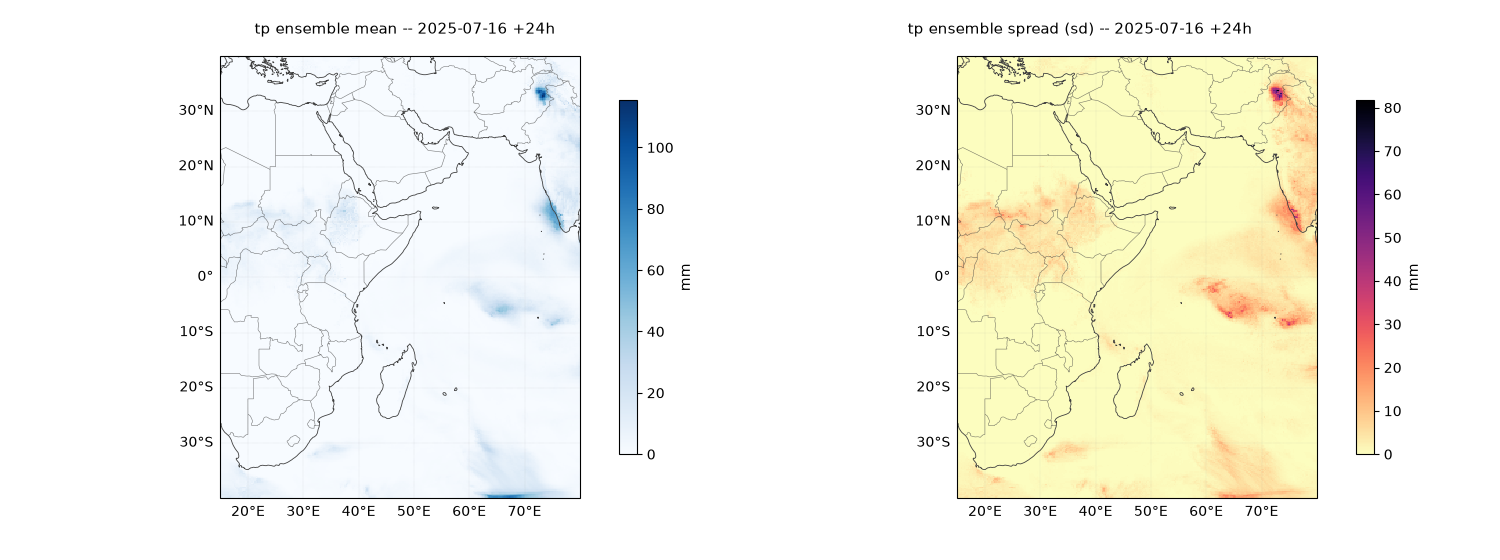

In [10]:
fig = plt.figure(figsize=(15, 5.6))
for pos, fld, title, cmap in (
        ((1, 2, 1), ens_mean, "ensemble mean", "Blues"),
        ((1, 2, 2), ens_sd, "ensemble spread (sd)", "magma_r")):
    ax = make_ax(fig, pos)
    kw = dict(transform=ccrs.PlateCarree()) if HAVE_CARTOPY else {}
    # pcolormesh, NOT contourf. Two reasons, and the second is the practical one:
    #   1. the field IS cells, 0.25 deg wide -- contours imply a smoothness the
    #      data does not have;
    #   2. contour polygons get clipped against the map boundary, and on some
    #      cartopy/GEOS builds that raises
    #        GEOSException: Points of LinearRing do not form a closed linestring
    #      at DRAW time, so the cell runs and then fails when the figure renders.
    #      A quadmesh is not clipped that way.
    m = ax.pcolormesh(fld["longitude"], fld["latitude"], fld.values,
                      cmap=cmap, shading="nearest", **kw)
    add_boundaries(ax)
    fig.colorbar(m, ax=ax, label="mm", shrink=0.80, pad=0.06)
    # fig.text, not ax.set_title: with draw_labels gridlines, cartopy can drop
    # the axes title entirely.
    fig.text(0.27 if pos[2] == 1 else 0.72, 0.94,
             f"tp {title} -- {str(date)[:10]} +{int(steps_h[8])}h",
             ha="center", fontsize=11)

# NOTE: no plt.tight_layout() and no savefig(bbox_inches="tight") here. Both
# re-run the layout after the map boundary is set; the first raises the same
# GEOS exception, the second silently drops the map. subplots_adjust does not.
fig.subplots_adjust(left=0.04, right=0.97, top=0.90, wspace=0.12)
plt.show()

That is the point of keeping all 51 members rather than a mean: the **spread**
is the signal a probabilistic model trains on. A deterministic store would have
thrown it away.


## 6. Seasons that span two stores

A season split across an era boundary, or extended after the source caught up,
lives in two sub-stores. Grid, steps and channels are identical, so
`xr.concat` on `time` is all that is needed.


In [12]:
pairs = [(s, s + "-tail") for s in SUBS if s + "-tail" in SUBS]
pairs += [(a, b) for a in SUBS for b in SUBS
          if b.endswith("-tail") and a.split("-", 1)[1] == b.split("-", 1)[1].replace("-tail", "")
          and (a, b) not in pairs]

for a, b in pairs:
    _, _, da = open_sub(a)
    _, _, db = open_sub(b)
    joined = xr.concat([da, db], dim="time")
    ta = pd.to_datetime(da.time.values)
    tb = pd.to_datetime(db.time.values)
    tj = pd.to_datetime(joined.time.values)
    print(f"{a:<20} {len(ta):>3} days  {ta.min().date()}..{ta.max().date()}")
    print(f"{b:<20} {len(tb):>3} days  {tb.min().date()}..{tb.max().date()}")
    print(f"{'-> concatenated':<20} {len(tj):>3} days  {tj.min().date()}..{tj.max().date()}"
          f"   monotonic: {tj.is_monotonic_increasing}\n")


50r1-jja2026          33 days  2026-06-01..2026-07-03
50r1-jja2026-tail     51 days  2026-07-04..2026-08-23
-> concatenated       84 days  2026-06-01..2026-08-23   monotonic: True



49r1-mam2026          73 days  2026-03-01..2026-05-12
50r1-mam2026-tail     19 days  2026-05-13..2026-05-31
-> concatenated       92 days  2026-03-01..2026-05-31   monotonic: True



## 7. Checking coverage — the trap

**The `time` axis is preallocated to the whole season.** A date that was never
written is therefore *not* absent: it is on the axis, `.sel()` finds it, and it
reads back as all-NaN. Nothing raises.

So `ds.sizes["time"]` tells you the axis length, not the coverage. Neither does
`.data_vars`. The manifest knows exactly which chunks exist, and
`session.chunk_coordinates` enumerates them **without fetching any of them**.


In [13]:
async def written_pairs(session, channel, attempts=5):
    """(time_idx, step_idx) this channel has chunks for. Manifest only.

    Retried: source.coop returns sporadic 500s and one mid-scan aborts the
    whole enumeration.
    """
    for attempt in range(attempts):
        try:
            out = set()
            async for c in session.chunk_coordinates(f"/{channel}"):
                out.add(tuple(c)[:2])
            return out
        except Exception:
            if attempt == attempts - 1:
                raise
            await asyncio.sleep(2 ** attempt)


sub = "49r1-jja2025"
repo_c, sess_c, ds_c = open_sub(sub)
nt, ns = ds_c.sizes["time"], ds_c.sizes["step"]

t1 = time.time()
have = await written_pairs(sess_c, "tp")   # top-level await: asyncio.run() raises in a kernel
days_with_data = len({t for t, _ in have})

print(f"{sub}: axis says {nt} days")
print(f"  chunks present for tp : {len(have):,} of {nt * ns:,} (date, step) pairs")
print(f"  days actually written : {days_with_data} of {nt}")
print(f"  -> {'COMPLETE' if len(have) == nt * ns else 'INCOMPLETE'}"
      f"   (manifest scan {time.time() - t1:.1f}s, no chunk data read)")


49r1-jja2025: axis says 92 days
  chunks present for tp : 5,980 of 5,980 (date, step) pairs
  days actually written : 92 of 92
  -> COMPLETE   (manifest scan 1.2s, no chunk data read)


In [14]:
# Confirm the manifest against the bytes: a written date is finite.
ti = sorted({t for t, _ in have})[0]
field = ds_c["t850"].isel(time=ti, step=1, number=0).values
print(f"t850 on {str(ds_c.time.values[ti])[:10]}: "
      f"finite fraction {np.isfinite(field).mean():.3f}, "
      f"range {np.nanmin(field):.1f}..{np.nanmax(field):.1f} K")


t850 on 2025-06-01: finite fraction 1.000, range 270.8..304.2 K


Use this whenever coverage matters. It is the only cheap way to tell a written
date from an unwritten one, and it reads the manifest rather than terabytes of
chunks.


## 8. How big is this, really

Three numbers, and only one of them answers *how much data is this*.


In [15]:
dense = 0
for sub in SUBS:
    _, _, d = open_sub(sub)
    dense += d.nbytes

stored = inv.GB.sum() / 1000.0        # TB actually hosted
days = int(inv.days.sum())
print(f"stored on source.coop      : {stored:8.2f} TB   <- what you download")
print(f"dense float32 (ds.nbytes)  : {dense/1e12:8.2f} TB   <- if uncompressed")
print(f"compression ratio          : {dense/1e12/stored:8.1f}x")
print()
print(f"forecast days              : {days:8d}")
print(f"per forecast day           : {stored*1000/days:8.1f} GB")
print("  = 38 channels x 51 members x 65 steps x 321 x 261 float32")

stored on source.coop      :     9.42 TB   <- what you download
dense float32 (ds.nbytes)  :    22.97 TB   <- if uncompressed
compression ratio          :      2.4x

forecast days              :      544
per forecast day           :     17.3 GB
  = 38 channels x 51 members x 65 steps x 321 x 261 float32


`ds.nbytes` describes a dense in-memory array that does not exist on disk —
quote the **stored** figure. Per forecast day is the number to plan with: it
tells you what one more season costs.


## 9. A worked example: rainfall over one point

Everything together — pick a location, pull the full ensemble across lead
times, and look at how the forecast spread grows.


pulled (65, 51) (members x steps) in 47.3s


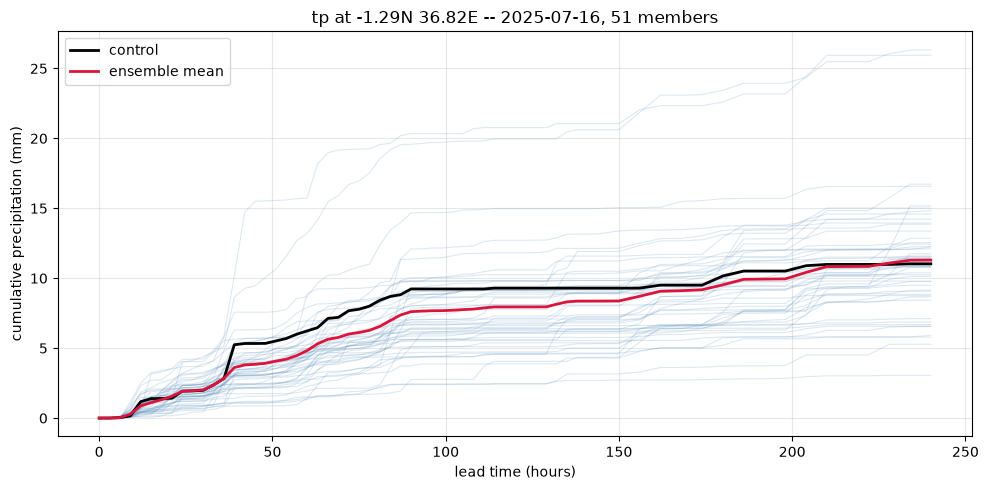

In [16]:
LAT, LON = -1.29, 36.82        # Nairobi
_, _, dj = open_sub("49r1-jja2025")

t1 = time.time()
series = (dj["tp"]
          .sel(latitude=LAT, longitude=LON, method="nearest")
          .isel(time=45)
          .compute()) * 1000.0        # m -> mm, cumulative
print(f"pulled {series.shape} (members x steps) in {time.time() - t1:.1f}s")

lead = (pd.to_timedelta(dj.step.values) / pd.Timedelta("1h")).astype(int)
fig, ax = plt.subplots(figsize=(10, 5))
for m in range(series.sizes["number"]):
    ax.plot(lead, series.isel(number=m), color="steelblue", alpha=0.18, lw=0.8)
ax.plot(lead, series.isel(number=0), color="black", lw=2, label="control")
ax.plot(lead, series.mean("number"), color="crimson", lw=2, label="ensemble mean")
ax.set_xlabel("lead time (hours)")
ax.set_ylabel("cumulative precipitation (mm)")
ax.set_title(f"tp at {LAT}N {LON}E -- {str(dj.time.values[45])[:10]}, 51 members")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. From 38 channels to six questions — Layer 2 to Layer 3

Everything above reads the store. This section reads it **the way CRMA does**,
and it is the step that turns a forecast into evidence.

| | | |
|---|---|---|
| **Layer 2** | this store | **17.3 GB** per initialisation |
| **Layer 3** | one Parquet table of features per basin | **8.8 MB** per initialisation |

About **870x smaller**, in ~9 minutes per initialisation. That ratio is not
compression: it is a measurement of how much of Layer 2 was ever *evidence*.

The reduction is organised as **six nodes**, and a node is a **physical concept,
not a model variable**:

| # | node | the question it asks |
|---|---|---|
| 1 | **moisture** | is there enough water in the air? |
| 2 | **transport** | is it being carried in, and does it converge? |
| 3 | **disturbance** | is there a coherent cyclonic system? |
| 4 | **vertical** | is the deep circulation helping or suppressing? |
| 5 | **convective** | can air rise vigorously? |
| 6 | **precipitation** | what does the model actually rain? |

Three variables describing one wind field are **one** piece of evidence, not
three. A network that treats them as three becomes confident for no reason, and
that is the single most important design decision behind these six.

Named systems — the Somali jet, the Turkana jet, the Mascarene ridge — are
**readings of** nodes 2 and 4, never nodes themselves.

The same six nodes serve **seven hazard propositions** (`hazards/README.md`):
heavy rain is the built one, dry spell and convective wind are designed on the
identical evidence. Layer 2 to Layer 3 is the expensive step, and it is paid
once for all of them.

**This section is self-contained.** Four files sit beside this notebook and
nothing else is needed -- no clone of the pipeline, no geopandas, no PROJ:

| file | what it is |
|---|---|
| `crma_evidence.py` | the evidence layer in one module: the sub-stores, the lead windows, the synoptic boxes, the weighted statistics, and one worked node |
| `data/region_cells_lev04_0p25.parquet` | the region-to-cell weights, 63,478 rows, 72 kB -- the **production** weights, so the numbers below are the archived ones |
| `data/basins_lev04_icpac.geojson` | the 55 catchment outlines, simplified to ~2 km, **for drawing only** |
| `data/layer3_sample_2026-03-03_D1_tcwv.parquet` | a slice of the shipped Layer 3 table, so the comparison at the end runs anywhere |

The module is a faithful copy of four files in the pipeline it documents. That
is a checkable claim rather than a promise, and section 12 checks it.

In [11]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))     # this notebook's own folder

import crma_evidence as ce              # the evidence layer, one self-contained file

print(ce.NODE_SUMMARY.to_string(index=False))
print(f"\nchannels the six nodes read: {len(ce.CHANNELS_READ)} of 38 stored")
print("   " + "  ".join(ce.CHANNELS_READ))
print(f"\nfeatures emitted per region per window: {ce.NODE_SUMMARY.features.sum()}")

         node                                      concept  channels  fields  features              scopes
     moisture                        Moisture availability         7       7        13 hydrobasin+synoptic
    transport Low-level moisture transport and convergence        11      15        23 hydrobasin+synoptic
  disturbance           Cyclonic / disturbance circulation         4       5        12 hydrobasin+synoptic
     vertical                   Vertical dynamical support         8       8        16 hydrobasin+synoptic
   convective       Thermodynamic / convective environment         8       7        12 hydrobasin+synoptic
precipitation                      Predicted precipitation         1       3        10          hydrobasin

channels the six nodes read: 32 of 38 stored
   cape  d200  d700  d850  gh500  msl  q500  q700  q850  q925  r700  r850  t2m  t500  t700  t850  tcwv  tp  u10  u200  u700  u850  u925  v10  v200  v700  v850  v925  vo500  vo700  vo850  w700

features emi

**32 of the 38 channels are read**; six are stored and never touched by these
nodes (`lsm`, `ro`, `skt`, `sp`, `u500`, `v500`). And the six nodes declare 86
statistics, of which the archive carries 81 per region per window — the
difference is the precipitation node, which is `hydrobasin`-scoped only:
rainfall over the Somali jet box is not evidence about anything.

## 11. Two kinds of region, and why they are not the same kind

A number becomes evidence only when it is attached to a place. This pipeline
uses **two** kinds of place, deliberately:

- **HydroBASINS level 4 catchments** — where a decision is reported. Filtered
  twice: a basin must touch one of the eleven ICPAC states *and* lie inside the
  forecast domain, because a basin fully inside a member state can still be
  mostly outside the grid. Above 5,000 km2 (a 0.25 deg cell is ~775 km2, so
  that is ~8 cells).
- **Synoptic boxes** — where the *circulation* is read. The Somali jet is not a
  catchment; asking for its basin-mean vorticity is a category error.

A basin is hydrology. A box is meteorology. Reducing both to "region" in one
table is fine; conflating what they mean is not.

The selection ran once, upstream: `bn-evidence/regions.py` reads HydroBASINS,
applies both filters, and overlays the polygons on the 0.25 deg grid in an
equal-area projection to get a fractional weight per cell. **That result is what
ships here**, so this notebook never needs geopandas, shapely or a working PROJ
data directory -- the one dependency whose silent failure would corrupt every
weight without raising anything.

`ce.build_region_cells(lat, lon)` will redo the overlay against the simplified
outlines if you need a different grid or a different `CORE_FRACTION` -- it is
the one function here that does want geopandas. Read its docstring first: the
simplified geometry moves 1,876 cell weights by more than 0.01 and shifts the
check at the end of section 12 from zero to about 0.9 mm. **The shipped weights
are the archived ones; a rebuild from these outlines is a good approximation of
them.**

In [12]:
# The 55 catchments ship as GeoJSON; the eleven boxes are a dict in the module.
shapes = ce.load_basin_shapes()
areas = np.array([s["area_km2"] for s in shapes])
print(f"HydroBASINS level 4, >= 5,000 km2, touching the ICPAC-11: {len(shapes)} catchments")
print(f"  total area {areas.sum():,.0f} km2, median {np.median(areas):,.0f} km2, "
      f"largest {areas.max():,.0f} km2")

print(f"\nsynoptic boxes: {len(ce.SYNOPTIC_LOCI)}")
for k, v in ce.SYNOPTIC_LOCI.items():
    print(f"   {k:<20} lat {v['lat'][0]:>6.1f}..{v['lat'][1]:<6.1f} "
          f"lon {v['lon'][0]:>5.1f}..{v['lon'][1]:<5.1f}")

HydroBASINS level 4, >= 5,000 km2, touching the ICPAC-11: 55 catchments
  total area 8,877,102 km2, median 111,056 km2, largest 797,089 km2

synoptic boxes: 11
   somali_jet           lat   -5.0..12.0   lon  40.0..55.0 
   turkana_corridor     lat    0.0..8.0    lon  33.0..38.0 
   arabian_sea          lat    5.0..20.0   lon  55.0..70.0 
   wio_moisture         lat  -10.0..5.0    lon  45.0..65.0 
   mozambique_channel   lat  -25.0..-12.0  lon  35.0..45.0 
   madagascar_east      lat  -25.0..-10.0  lon  50.0..65.0 
   mascarene_sector     lat  -38.0..-25.0  lon  40.0..75.0 
   congo_upstream       lat   -8.0..5.0    lon  18.0..30.0 
   itcz_east_africa     lat   -5.0..15.0   lon  30.0..45.0 
   red_sea_arabian      lat   20.0..30.0   lon  30.0..60.0 
   swio_cyclone_belt    lat  -25.0..-8.0   lon  45.0..80.0 


In [13]:
INIT, WINDOW = "2026-03-03", "D1"          # one initialisation, one lead window

# ce.open_store resolves which of the eight sub-stores holds this date.
store = ce.open_store(ce.era_for(INIT))
lat, lon = store["latitude"].values, store["longitude"].values

# The cell weights ship precomputed -- passing lat/lon CHECKS the grid they were
# built for rather than assuming it. A silent mismatch would misplace every cell.
basin_regions = ce.load_regions("hydrobasin", lat=lat, lon=lon)
loci = ce.load_regions("synoptic", lat=lat, lon=lon)
print(f"{len(basin_regions)} basins and {len(loci)} synoptic boxes, "
      f"resolved on the {lat.size} x {lon.size} grid at 0.25 deg")

d = pd.DataFrame([dict(region_id=r.region_id, km2=round(r.area_km2), cells=r.n_cells,
                       core=r.n_core, w_sum=round(float(r.w.sum()), 1))
                  for r in basin_regions])
print("\nfive largest basins:")
print(d.nlargest(5, "km2").to_string(index=False))
print("\nfive smallest:")
print(d.nsmallest(5, "km2").to_string(index=False))
print(f"\ncells per basin: min {d.cells.min()}, median {int(d.cells.median())}, "
      f"max {d.cells.max()}")
print(f"core cells (w >= {ce.CORE_FRACTION}): min {d.core.min()}, "
      f"median {int(d.core.median())}")

55 basins and 11 synoptic boxes, resolved on the 321 x 261 grid at 0.25 deg

five largest basins:
       region_id    km2  cells  core  w_sum
hybas_1040034260 797089   1238  1157 1103.0
hybas_1041156950 648276    962   896  842.3
hybas_1040837630 615820    890   842  809.8
hybas_1040837890 552625    812   754  716.0
hybas_1041259940 453078    671   624  595.2

five smallest:
       region_id   km2  cells  core  w_sum
hybas_1040007060  6517     18    10    8.5
hybas_1040006860  7038     21    12    9.2
hybas_1040007070  7800     21    12   10.2
hybas_1040044540 16877     36    28   22.3
hybas_1041139500 23961     55    39   31.0

cells per basin: min 18, median 194, max 1238
core cells (w >= 0.25): min 10, median 173


**Cells per basin runs from 18 to 1,238.** That spread is why every statistic
carries the count behind it: a p95 over 18 cells and a p95 over 1,238 are not
the same claim, and nothing downstream can tell them apart from the value alone.

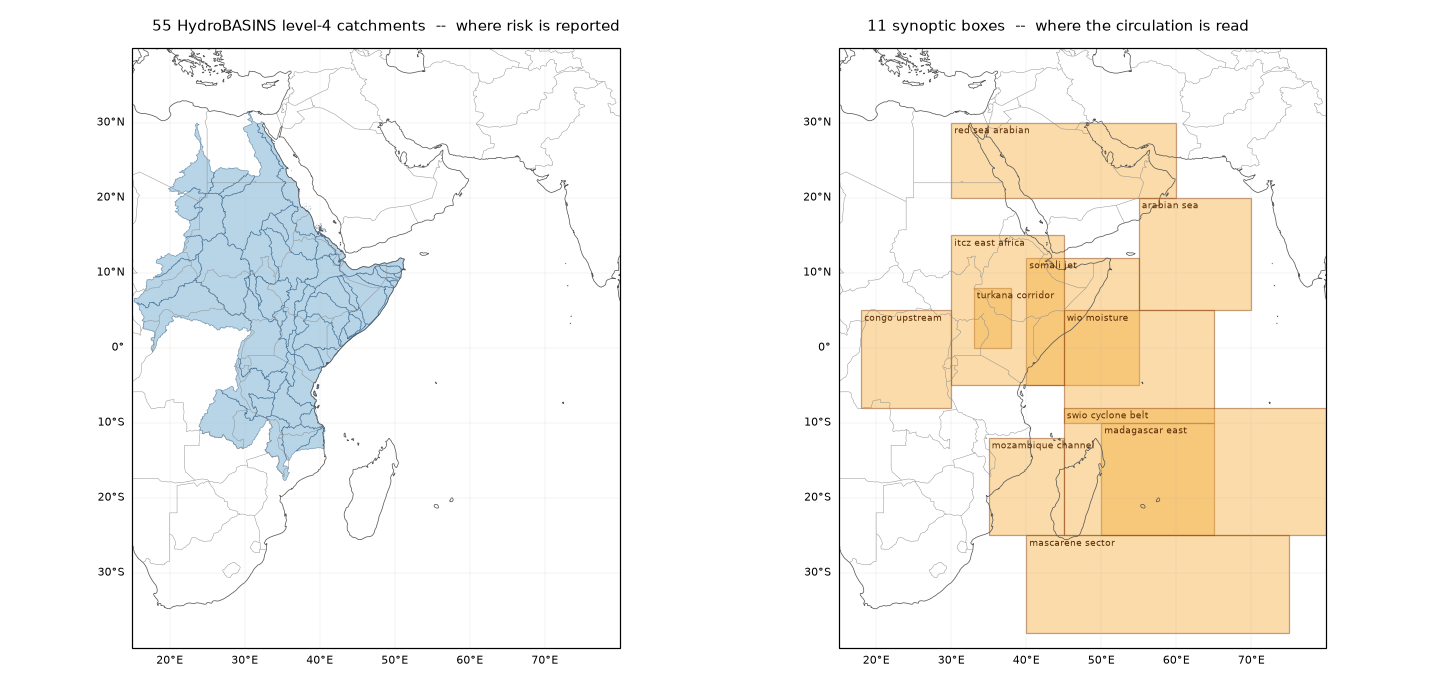

In [14]:
# The two region types, side by side, at the same scale. The outlines are drawn
# straight from the GeoJSON rings -- no geopandas, no shapely.
fig = plt.figure(figsize=(13, 6.2))
for i, what in enumerate(("basins", "boxes")):
    ax = make_ax(fig, (1, 2, i + 1))
    if HAVE_CARTOPY:
        ax.add_feature(cfeature.COASTLINE.with_scale("50m"), lw=0.5, edgecolor="0.35")
        ax.add_feature(cfeature.BORDERS.with_scale("50m"), lw=0.3, edgecolor="0.55")
        gl = ax.gridlines(draw_labels=True, lw=0.25, color="0.7", ls=":")
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {"size": 7}
    tr = dict(transform=ccrs.PlateCarree()) if HAVE_CARTOPY else {}
    if what == "basins":
        for s in shapes:
            for ring in s["rings"]:
                ax.fill(ring[:, 0], ring[:, 1], facecolor="#7fb3d5", edgecolor="#1f4e79",
                        alpha=0.55, linewidth=0.4, **tr)
    else:
        for k, v in ce.SYNOPTIC_LOCI.items():
            ax.add_patch(plt.Rectangle((v["lon"][0], v["lat"][0]),
                                       v["lon"][1] - v["lon"][0],
                                       v["lat"][1] - v["lat"][0],
                                       facecolor="#f5b041", edgecolor="#873600",
                                       alpha=0.45, lw=0.8, **tr))
            ax.text(v["lon"][0] + 0.4, v["lat"][1] - 1.4, k.replace("_", " "),
                    fontsize=6.2, color="#5b2c06", **tr)

fig.text(0.27, 0.955, "55 HydroBASINS level-4 catchments  --  where risk is reported",
         ha="center", fontsize=10)
fig.text(0.74, 0.955, "11 synoptic boxes  --  where the circulation is read",
         ha="center", fontsize=10)
# subplots_adjust, not tight_layout -- see the note in section 5.
fig.subplots_adjust(left=0.05, right=0.97, top=0.93, bottom=0.05, wspace=0.16)
plt.show()

## 12. One initialisation, computed here

Four steps, and `build_evidence.py` is these four in a loop over six nodes and
five lead windows:

1. **derive** — `node.build()` computes what is not stored: column-integrated
   moisture, moisture-flux convergence, cyclonic vorticity signed so that
   "cyclonic" means the same in both hemispheres, lapse rates.
2. **collapse time** into a lead window (D1, D2-3, D4-5, D6-7, D8-10) — the
   pooling is *inside* the statistic, so it cannot be undone afterwards.
3. **collapse space** onto regions, in an equal-area projection.
4. **summarise** — mean, p90, p95, max, exceedance fractions.

The 51 members are kept through all four. They are the evidence.

In [15]:
print(f"init {INIT}   window {WINDOW}   lead hours {list(map(int, ce.window_steps(WINDOW)))}")
channels = ("tcwv", "q925", "q850", "q700", "q500", "r850", "r700")
print(f"node 'moisture' reads {len(channels)} channels: {', '.join(channels)}")

t0 = time.time()
dsw = ce.load_window(store, INIT, WINDOW, channels)
print(f"\nload_window -> {dict(dsw.sizes)}   ({time.time() - t0:.1f}s)")

t0 = time.time()
diag = ce.moisture(dsw)
print(f"ce.moisture -> {len(diag.data_vars)} fields: {', '.join(diag.data_vars)}"
      f"   ({time.time() - t0:.1f}s)")
print("   the last two are DERIVED, not stored: q_int (column moisture) and")
print("   moist_depth (how deep the moist layer is)")

t0 = time.time()
tbl = ce.reduce_field(diag["tcwv"], basin_regions, ["mean", "p90"], feature_prefix="tcwv")
print(f"\nreduce_field(tcwv, {len(basin_regions)} basins, [mean, p90]) "
      f"-> {tbl.shape[0]:,} rows   ({time.time() - t0:.1f}s)")
print(tbl.head(4).to_string(index=False))

init 2026-03-03   window D1   lead hours [6, 12, 18, 24]
node 'moisture' reads 7 channels: tcwv, q925, q850, q700, q500, r850, r700

load_window -> {'lon': 261, 'lat': 321, 'number': 51, 'valid_time': 4}   (62.9s)
ce.moisture -> 9 fields: tcwv, q925, q850, q700, q500, r850, r700, q_int, moist_depth   (0.1s)
   the last two are DERIVED, not stored: q_int (column moisture) and
   moist_depth (how deep the moist layer is)

reduce_field(tcwv, 55 basins, [mean, p90]) -> 5,610 rows   (0.2s)
       region_id region_type   feature  member     value
hybas_1040000010  hydrobasin tcwv_mean       0 13.620611
hybas_1040000010  hydrobasin tcwv_mean       1 13.560546
hybas_1040000010  hydrobasin tcwv_mean       2 13.387780
hybas_1040000010  hydrobasin tcwv_mean       3 13.610933


### The two statistic families are computed over different cells

This is invisible in the Parquet and it changes what a number means:

- a **mean** is area-weighted over **every overlapping cell**, each weighted by
  the fraction `w` of it inside the polygon, then averaged over the window's
  steps;
- an **order statistic** (p90, p95, max) uses **only core cells** — those with
  `w >= 0.25` — and pools space *and* time before taking the percentile.

So a basin mean and a basin p95 do not describe the same set of cells. Both are
right; they answer different questions. *Is anywhere in this basin at risk* is
the max; *how much of it* is the p95.

In [16]:
# One basin, one member, both statistics, by hand.
r = min(basin_regions, key=lambda x: abs(x.n_cells - 60))   # small enough to see
vals = np.asarray(diag["tcwv"].transpose("number", "valid_time", "lat", "lon").values,
                  dtype="float32")
m = 0                                                        # the control member

print(f"basin {r.region_id}: {r.area_km2:,.0f} km2, {r.n_cells} overlapping cells, "
      f"{r.n_core} core (w >= {ce.CORE_FRACTION})")
print(f"weights w: min {r.w.min():.3f}  max {r.w.max():.3f}  sum {r.w.sum():.2f}")

cells = vals[m][:, r.iy, r.ix]                               # (steps, cells)
by_hand_mean = float(np.nansum((cells * r.w).sum(axis=0) / cells.shape[0])
                     / np.nansum(r.w))
core_vals = vals[m][:, r.iy[r.core], r.ix[r.core]].ravel()   # core cells, all steps
by_hand_p90 = float(np.nanpercentile(core_vals, 90))

got = tbl[(tbl.region_id == r.region_id) & (tbl.member == m)].set_index("feature").value
print("\n                       by hand     reduce_field")
print(f"  tcwv_mean   {by_hand_mean:12.6f}   {got['tcwv_mean']:12.6f}")
print(f"  tcwv_p90    {by_hand_p90:12.6f}   {got['tcwv_p90']:12.6f}")

basin hybas_1040040660: 31,900 km2, 62 overlapping cells, 47 core (w >= 0.25)
weights w: min 0.011  max 1.000  sum 41.38

                       by hand     reduce_field
  tcwv_mean      44.497696      44.497696
  tcwv_p90       48.681595      48.681595


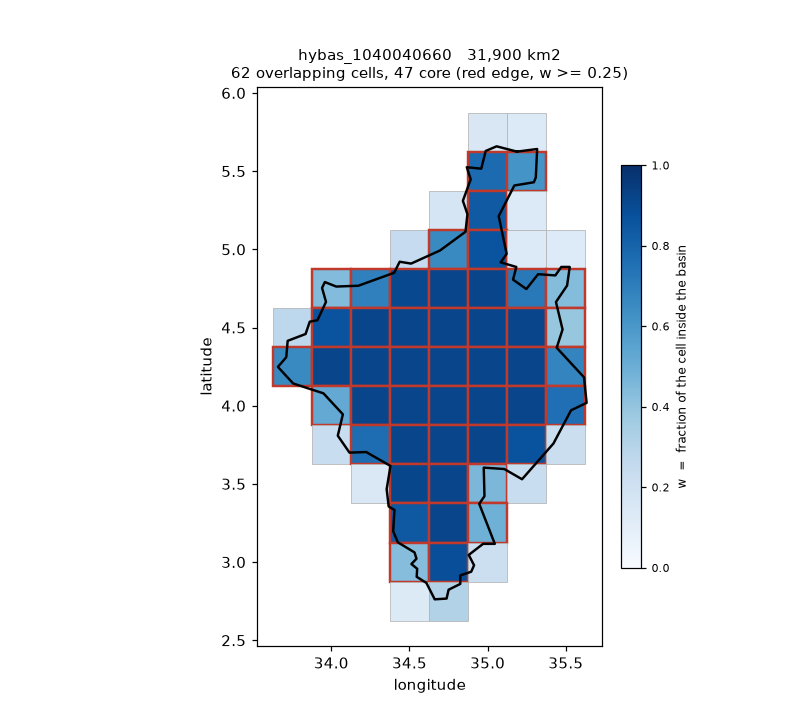

In [17]:
# The same basin at cell resolution: what the weights actually are.
rings = next(s["rings"] for s in shapes if s["region_id"] == r.region_id)
fig, ax = plt.subplots(figsize=(7.2, 6.6))
cmap = plt.cm.Blues
for iy, ix, w, core in zip(r.iy, r.ix, r.w, r.core):
    ax.add_patch(plt.Rectangle((lon[ix] - 0.125, lat[iy] - 0.125), 0.25, 0.25,
                               facecolor=cmap(0.12 + 0.80 * float(w)),
                               edgecolor="#c0392b" if core else "0.70",
                               lw=1.6 if core else 0.5, zorder=1))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cb = fig.colorbar(sm, ax=ax, shrink=0.72, pad=0.03)
cb.set_label("w  =  fraction of the cell inside the basin", fontsize=8)
cb.ax.tick_params(labelsize=7)
for ring in rings:
    ax.plot(ring[:, 0], ring[:, 1], color="black", lw=1.6, zorder=2)

ax.set_aspect("equal")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"{r.region_id}   {r.area_km2:,.0f} km2\n"
             f"{r.n_cells} overlapping cells, {r.n_core} core "
             f"(red edge, w >= {ce.CORE_FRACTION})", fontsize=9.5)
plt.show()

Every shaded cell contributes to the **mean**, weighted by its shading. Only the
red-edged **core** cells carry the p90. The pale cells around the rim are real
grid cells that are mostly outside the catchment — they move the mean a little
and the percentile not at all.

In [18]:
# The shipped Layer 3 values for the same initialisation, window and feature --
# built by build_evidence.py, which is the loop above run over six nodes and
# five windows. A slice of it travels with this notebook so the check runs
# anywhere; the full table is in the repository under layer3/.
arc = pd.read_parquet(ce.DATA / "layer3_sample_2026-03-03_D1_tcwv.parquet")
print(f"data/layer3_sample_2026-03-03_D1_tcwv.parquet: {len(arc):,} rows, "
      f"{arc.feature.nunique()} features x {arc.region_id.nunique()} basins "
      f"x {arc.member.nunique()} members")
print(arc.head(3).to_string(index=False))

mm = tbl.merge(arc, on=["region_id", "feature", "member"], suffixes=("_here", "_archive"))
diff = (mm.value_here - mm.value_archive).abs()
print(f"\nrecomputed here vs the shipped archive, {WINDOW}:")
print(f"  {len(mm):,} rows matched over {mm.feature.nunique()} features, "
      f"max |difference| = {diff.max():.3e}")
print("  -- the same weights and the same code, so the same numbers, to the last bit.")

full = Path.cwd().parent / "layer3" / "medium-range-v2" / f"ens_{INIT}_lev04.parquet"
if full.exists():
    a = pd.read_parquet(full)
    print(f"\nand the full table for this initialisation, {full.name}:")
    print(f"  {len(a):,} rows = {a.feature.nunique()} features x {a.region_id.nunique()} "
          f"regions x {a.member.nunique()} members x {a.window.nunique()} windows")
    print(f"  nodes: {', '.join(sorted(a.node.unique()))}")

data/layer3_sample_2026-03-03_D1_tcwv.parquet: 6,732 rows, 2 features x 66 basins x 51 members
 init_time        region_id region_type   feature  member     value     node window
2026-03-03 hybas_1040000010  hydrobasin tcwv_mean       0 13.620611 moisture     D1
2026-03-03 hybas_1040000010  hydrobasin tcwv_mean       1 13.560546 moisture     D1
2026-03-03 hybas_1040000010  hydrobasin tcwv_mean       2 13.387780 moisture     D1

recomputed here vs the shipped archive, D1:
  5,610 rows matched over 2 features, max |difference| = 0.000e+00
  -- the same weights and the same code, so the same numbers, to the last bit.

and the full table for this initialisation, ens_2026-03-03_lev04.parquet:
  1,335,180 rows = 81 features x 66 regions x 51 members x 5 windows
  nodes: convective, disturbance, moisture, precipitation, transport, vertical


**Bit-identical** -- and that is the claim `crma_evidence.py` exists to make
checkable. The weights are the production weights and the arithmetic is a
faithful copy, so a feature computed here *is* the archived value rather than an
approximation of it. Had the copy drifted, this line would show it.

(The weights ship as float64 for exactly that reason. Rounded to float32 they
are 20 kB smaller and the difference above becomes 2.1e-08 instead of zero.)

One initialisation of Layer 3 is **1,335,180 rows**: 81 features x 66 regions x
51 members x 5 windows, 8.8 MB of Parquet, about nine minutes of wall clock.
Ninety-two of those is one season, and **93% of the whole pipeline's compute**
is this one step.

## 13. Handover — what consumes Layer 3

Layer 3 is not the product. It is the evidence a Bayesian network reasons over,
and the chain from here is cheap: **under four minutes of fitting** against the
fourteen hours that produced the tables.

```
   this store  ──►  Layer 3          ──►  Layer 4        ──►  Layer 5
   (17.3 GB)        (8.8 MB/init)         (0.05 MB/init)      one of four states
                    1.23 M rows           275 rows            per basin x window
```

**How the network reads a Layer 3 table.** Per basin and lead window:

1. **score every member** — each node's features are z-scored and combined into
   one weighted composite per member (`node_information.py` sets the weights
   from each feature's rank correlation with observed rainfall);
2. **bin each member** into five ordinal states at fitted percentile edges;
3. **the histogram over the 51 members *is* the soft evidence** — nothing about
   the spread is assumed, which is why the store keeps every member;
4. **combine the five circulation nodes** with a noisy-OR: 21 fitted numbers
   instead of a 3,125-row table, and because it is a product, each node's
   contribution comes out in **decibels that add** — the audit trail;
5. **update with the model's own rainfall**, which hangs *below* the latent rain
   node as a **measurement** of it, discounted by a fitted reliability `alpha`
   because `tp` and the circulation nodes share one forecast's error;
6. **hand to the elicited half** — `(rain, antecedent) -> flood_hazard` in
   Julia, then a cost-loss rule gives `Monitor / Evaluate / Assess /
   Actionable_Risk`.

| script | what it does with Layer 3 |
|---|---|
| `node_information.py` | which features carry information, and with what sign |
| `measurement_matrix.py` | `P(tp reading \| truth)`, counted against satellite rainfall |
| `noisy_or_em.py` | the circulation -> heavy-rain link probabilities, by EM |
| `build_layer4.py` | the posterior per basin and window, with per-node decibels |
| `fit_measurement_alpha.py` | how far the model's own rainfall can be trusted |
| `to_admin1.py` | 227 ICPAC admin-1 units, with the basin trace-back |
| `run_layer4_batch.jl` | the elicited half and the cost-loss decision |

**What the store must keep for any of this to work**, and why the choices in
sections 1-9 are not incidental:

- **all 51 members** — step 3 is a histogram over them; a mean store would make
  soft evidence unavailable and the uncertainty unrecoverable;
- **both central and tail statistics** — a city-scale flood is under 1% of a
  211,000 km2 basin and a p95 cannot see it by construction, so the max is
  always carried beside it;
- **the whole step axis for accumulations** — return-period ratios run to 7-day
  durations, longer than any lead window, so `tp` is differenced on the full
  axis and only then attributed to a window.

Where to read further, in the same repository:

- `tutorial/bayesian_network.md` — the network from first principles, with the
  fitted numbers and a worked example reproducible by hand
- `tutorial/bn_concepts_in_code.md` — every Bayesian-network concept and the
  exact line that implements it
- `hazards/flood/RUNBOOK.md` and the top-level `RUNBOOK.md` — every command,
  with measured timings
- `hazards/README.md` — the other six propositions on this same evidence layer

## 14. What this notebook covered

- **Sections 1-9** — the store itself: open it anonymously, find the seasons,
  read a field, join a split season, check coverage honestly, and size it.
- **Sections 10-12** — the same store as the input to an evidence layer: six
  physical questions, two kinds of region, and one initialisation reduced from
  grid to table with the arithmetic shown rather than asserted.
- **Section 13** — what reads the result, and what the store must preserve for
  that to be possible.

The store is public and needs no credentials. Everything after it is in
`github.com/nishadhka/crma`.

## Gotchas

- **Open per sub-store, not once.** Each season is its own Icechunk repo. Use
  `xr.concat` to join a season split across two (section 6).
- **The `time` axis is preallocated.** An unwritten date reads as all-NaN and
  does not raise. Check coverage with `session.chunk_coordinates`, never with
  `ds.sizes["time"]` (section 7).
- **Latitude descends** (40N -> -40S). `slice(-10, 10)` returns nothing; you
  want `slice(10, -10)`.
- **Select `time` and `step` before computing.** One chunk is all 51 members at
  one (date, step); a careless selection across dates touches every chunk.
- **`from_env=False` is not optional.** Without it a stray `AWS_ENDPOINT_URL`
  in your environment silently redirects the open to the wrong host.
- **Disable the manifest preload**, or a sporadic source.coop 500 fails the
  open outright.
- **Retry manifest scans.** The same 500s abort a `chunk_coordinates`
  enumeration partway.
- **`cape` spans a rename.** ECMWF switched `cape` -> `mucape` on 2024-11-13;
  both are stored under `cape`, so no consumer action is needed — but a season
  crossing that date is the one to spot-check if values look wrong.
- **Do not quote `ds.nbytes`** as the data volume; it is the uncompressed dense
  size, several times what is stored.

### ...and when reducing to Layer 3

- **`ens.load_window` renames the coordinates.** It returns `lat`/`lon`/
  `valid_time`, not `latitude`/`longitude`/`step`, because a window is no longer
  indexed by lead.
- **A basin mean and a basin p95 are computed over different cell sets** (all
  overlapping cells vs core cells only). Section 12.
- **`pyproj` must be installed in the same environment**, with its PROJ data.
  An inherited one with no data directory makes the equal-area cell weighting
  fail *silently* -- wrong weights, no exception.
- **Delete `.sbn`/`.sbx` beside the HydroBASINS shapefile** if a bbox read
  raises `Invalid node descriptor size in .sbn`. It fires only on bbox reads.
- **Do not call `plt.tight_layout()` or save with `bbox_inches="tight"` on
  cartopy axes.** The first raises a GEOS exception, the second silently drops
  the map. Use `fig.subplots_adjust`.
